=== PRAKTIKUM 1: LAPORAN EVALUASI LENGKAP & KURVA ===


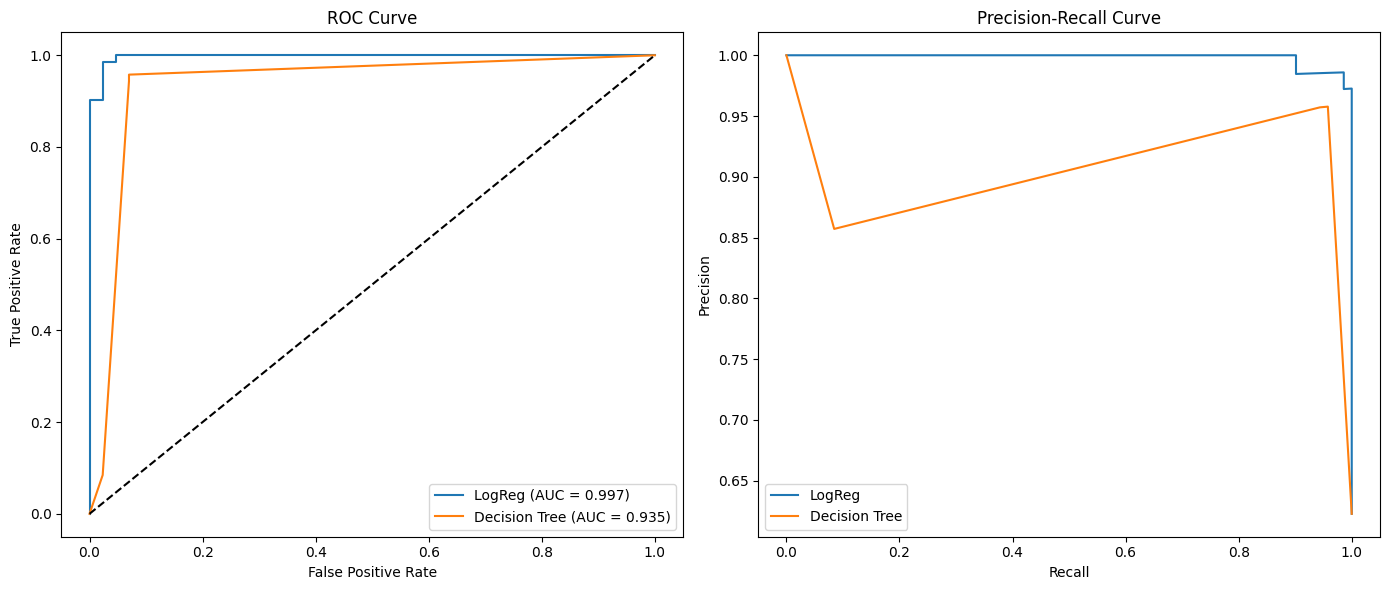


=== PRAKTIKUM 2: PERBANDINGAN 3 MODEL DENGAN STRATIFIED K-FOLD CV ===


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

Logistic Regression: F1 rata-rata = 0.960 (+/- 0.013)
Decision Tree: F1 rata-rata = 0.944 (+/- 0.016)
KNN: F1 rata-rata = 0.949 (+/- 0.015)


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [14]:
# ==========================================
# PRAKTIKUM BAB 7: EVALUASI & STRATIFIED K-FOLD
# ==========================================

import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report, f1_score,
    roc_curve, precision_recall_curve, auc
)

# Load dataset
data = load_breast_cancer()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scaling khusus untuk model yang butuh (misal Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("=== PRAKTIKUM 1: LAPORAN EVALUASI LENGKAP & KURVA ===")
# Latih model Logistic Regression dan Decision Tree
model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train_scaled, y_train)

model_dt = DecisionTreeClassifier(max_depth=5, random_state=42)
model_dt.fit(X_train, y_train)

# Prediksi probabilitas untuk ROC & PR Curve
y_prob_lr = model_lr.predict_proba(X_test_scaled)[:, 1]
y_prob_dt = model_dt.predict_proba(X_test)[:, 1]

# Plot ROC Curve & Precision-Recall Curve dalam satu figur gabungan
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. ROC Curve
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
axes[0].plot(fpr_lr, tpr_lr, label=f"LogReg (AUC = {auc(fpr_lr, tpr_lr):.3f})")
axes[0].plot(fpr_dt, tpr_dt, label=f"Decision Tree (AUC = {auc(fpr_dt, tpr_dt):.3f})")
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_title("ROC Curve")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()

# 2. Precision-Recall (PR) Curve
precision_lr, recall_lr, _ = precision_recall_curve(y_test, y_prob_lr)
precision_dt, recall_dt, _ = precision_recall_curve(y_test, y_prob_dt)
axes[1].plot(recall_lr, precision_lr, label="LogReg")
axes[1].plot(recall_dt, precision_dt, label="Decision Tree")
axes[1].set_title("Precision-Recall Curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

plt.tight_layout()
plt.show()


print("\n=== PRAKTIKUM 2: PERBANDINGAN 3 MODEL DENGAN STRATIFIED K-FOLD CV ===")
# Praktikum 7.6: Evaluasi 3 Model dengan Stratified K-Fold
model_list = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for nama, model in model_list.items():
    # Gunakan data scaled jika model adalah Logistic Regression atau KNN
    X_data = X_scaled if nama in ["Logistic Regression", "KNN"] else X

    skor = cross_val_score(model, X, y, cv=skf, scoring="f1")
    print(f"{nama}: F1 rata-rata = {skor.mean():.3f} (+/- {skor.std():.3f})")